# Review Sentiment Analyzer (Deep Learning)


## 1. Setup

In [ ]:
# Run once (remove the leading '#' if packages are missing)
#%pip install -q transformers torch pandas numpy matplotlib seaborn scikit-learn accelerate

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import pipeline
from datasets import Dataset

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ---- Configuration -------------------------------------------------------
DATA_PATH   = "amazon_reviews_labeled.csv"      # change if your file lives elsewhere
TEXT_COL    = "comment"
MODEL_ID    = "cardiffnlp/twitter-roberta-base-sentiment-latest"
BATCH_SIZE  = 16
MAX_LEN     = 128                    # social posts are short; 128 tokens is plenty
LOW_CONF    = 0.60                   # below this, flag a prediction for human review
LABELS      = ["negative", "neutral", "positive"]
PALETTE     = {"negative": "#d9534f", "neutral": "#9aa0a6", "positive": "#2e9d5b"}

DEVICE = 0 if torch.cuda.is_available() else -1
print(f"Torch {torch.__version__} | running on {'GPU' if DEVICE == 0 else 'CPU'}")

Torch 2.14.1+cpu | running on CPU


## 2. Load and explore the data

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])

print(f"{len(df)} rows, columns: {list(df.columns)}")
print("Missing values:\n", df.isna().sum().to_string())
print("Duplicate comments:", df[TEXT_COL].duplicated().sum())
df.head()

1500 rows, columns: ['review_id', 'product_id', 'product_name', 'category', 'platform', 'date', 'rating', 'title', 'comment', 'label', 'verified_purchase', 'helpful_votes']
Missing values:
 review_id            0
product_id           0
product_name         0
category             0
platform             0
date                 0
rating               0
title                0
comment              0
label                0
verified_purchase    0
helpful_votes        0
Duplicate comments: 0


,review_id,product_id,product_name,category,platform,date,rating,title,comment,label,verified_purchase,helpful_votes
0,R00001,PRD-0103,Skylark Home Cat Tree,Pet Supplies,Amazon,2025-01-01,5,Highly recommend,Received this as a gift. Honestly the material...,positive,True,1
1,R00002,PRD-0014,Pinecrest Classic Mattress Topper,Bedding,Amazon,2025-01-02,5,Great value,Ordered this mattress topper after reading a b...,positive,True,0
2,R00003,PRD-0032,Kestrel Travel Over-ear Headphones,Headphones & Earbuds,Amazon,2025-01-02,2,Broke too soon,"Very disappointed, the battery life is a letdo...",negative,True,4
3,R00004,PRD-0075,Northgate Pet Water Fountain,Pet Supplies,Amazon,2025-01-02,3,Decent for the price,"The stability is really good, but the size is ...",neutral,True,4
4,R00005,PRD-0099,Oakridge Plus Leggings,Clothing,Amazon,2025-01-02,5,Impressed so far,Arrived a day early and was packed really well...,positive,True,1


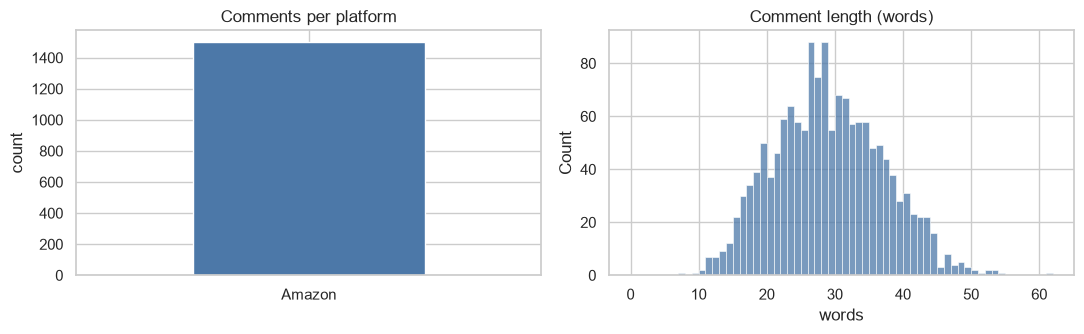

In [3]:
df["n_words"] = df[TEXT_COL].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["platform"].value_counts().plot.bar(ax=axes[0], color="#4c78a8", rot=0)
axes[0].set_title("Comments per platform"); axes[0].set_xlabel(""); axes[0].set_ylabel("count")

sns.histplot(df["n_words"], bins=range(0, df["n_words"].max() + 2), ax=axes[1], color="#4c78a8")
axes[1].set_title("Comment length (words)"); axes[1].set_xlabel("words")
plt.tight_layout(); plt.show()

## 3. Text normalisation

Transformers need very little cleaning. We deliberately **keep** emoji, punctuation and capitalisation
("AGAIN", "!!") because they carry sentiment. We only replace user handles and URLs with placeholders, which is the
same preprocessing the model saw during training.

In [4]:
def normalise(text: str) -> str:
    text = str(text).strip()
    text = re.sub(r"@\w+", "@user", text)            # handles -> @user
    text = re.sub(r"https?://\S+", "http", text)     # URLs    -> http
    text = re.sub(r"\s+", " ", text)                 # collapse whitespace
    return text

df["clean_text"] = df[TEXT_COL].map(normalise)
df[[TEXT_COL, "clean_text"]].head(3)

,comment,clean_text
0,Received this as a gift. Honestly the material...,Received this as a gift. Honestly the material...
1,Ordered this mattress topper after reading a b...,Ordered this mattress topper after reading a b...
2,"Very disappointed, the battery life is a letdo...","Very disappointed, the battery life is a letdo..."


## 4. Load the model and predict

The first run downloads the weights (~500 MB) from the Hugging Face Hub; after that they are cached.
`top_k=None` makes the pipeline return the probability of **every** class, not just the winner, so we can measure confidence.

In [ ]:
clf = pipeline(
    "text-classification",
    model=MODEL_ID,
    tokenizer=MODEL_ID,
    top_k=None,
    device=DEVICE,
)
print("Model labels:", clf.model.config.id2label)

In [6]:
# Some checkpoints expose generic names (LABEL_0/1/2); map them to readable ones.
GENERIC = {"LABEL_0": "negative", "LABEL_1": "neutral", "LABEL_2": "positive"}

def predict(texts, batch_size=BATCH_SIZE) -> pd.DataFrame:
    """Return a DataFrame of class probabilities + predicted label + confidence."""
    outputs = clf(list(texts), batch_size=batch_size, truncation=True, max_length=MAX_LEN)
    rows = []
    for scores in outputs:
        probs = {GENERIC.get(s["label"], s["label"]).lower(): s["score"] for s in scores}
        rows.append({lab: probs.get(lab, 0.0) for lab in LABELS})
    out = pd.DataFrame(rows)
    out["sentiment"] = out[LABELS].idxmax(axis=1)
    out["confidence"] = out[LABELS].max(axis=1)
    return out

preds = predict(df["clean_text"])
result = pd.concat([df.reset_index(drop=True), preds], axis=1)
result["net_score"] = result["positive"] - result["negative"]   # -1 (very negative) .. +1 (very positive)
result["needs_review"] = result["confidence"] < LOW_CONF
result[["platform", TEXT_COL, "sentiment", "confidence"]].round(3)

,platform,comment,sentiment,confidence
0,Amazon,Received this as a gift. Honestly the material...,positive,0.983
1,Amazon,Ordered this mattress topper after reading a b...,positive,0.980
2,Amazon,"Very disappointed, the battery life is a letdo...",negative,0.944
3,Amazon,"The stability is really good, but the size is ...",positive,0.811
4,Amazon,Arrived a day early and was packed really well...,positive,0.980
...,...,...,...,...
1495,Amazon,Picked this up on sale. Really pleased: the ea...,positive,0.985
1496,Amazon,Only downside: the replay value is a bit avera...,positive,0.823
1497,Amazon,"Picked this up on sale. Don't expect much, the...",negative,0.916
1498,Amazon,Really pleased: the size on the counter is spo...,positive,0.972


## 5. Analyse the results

### 5.1 Overall sentiment distribution

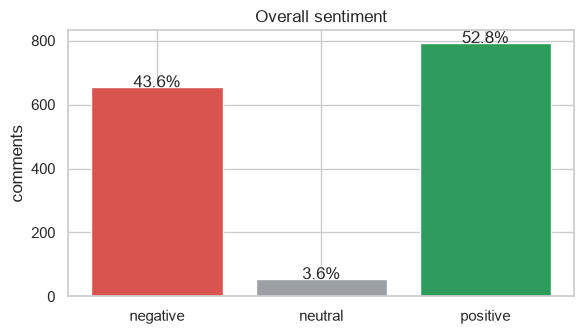

Average net sentiment score: +0.11  (range -1 to +1)


In [7]:
counts = result["sentiment"].value_counts().reindex(LABELS, fill_value=0)
pct = (counts / counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[l] for l in counts.index])
for b, p in zip(bars, pct):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.1, f"{p}%", ha="center")
ax.set_title("Overall sentiment"); ax.set_ylabel("comments")
plt.tight_layout(); plt.show()
print(f"Average net sentiment score: {result['net_score'].mean():+.2f}  (range -1 to +1)")

### 5.2 By platform

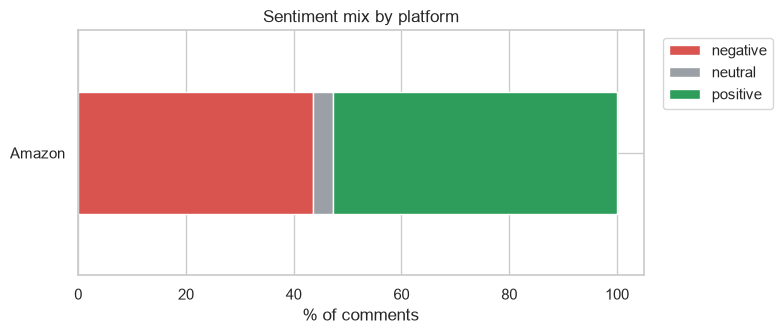

,comments,avg_net_score,avg_confidence
platform,,,
Amazon,1500,0.11,0.87


In [8]:
by_platform = (
    result.groupby(["platform", "sentiment"]).size()
          .unstack(fill_value=0).reindex(columns=LABELS, fill_value=0)
)
share = by_platform.div(by_platform.sum(axis=1), axis=0) * 100

ax = share.plot.barh(stacked=True, figsize=(8, 3.5), color=[PALETTE[l] for l in LABELS])
ax.set_xlabel("% of comments"); ax.set_ylabel(""); ax.set_title("Sentiment mix by platform")
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

summary = result.groupby("platform").agg(
    comments=("sentiment", "size"),
    avg_net_score=("net_score", "mean"),
    avg_confidence=("confidence", "mean"),
).round(2).sort_values("avg_net_score")
summary

### 5.3 Trend over time
Daily average of the net sentiment score (positive probability minus negative probability).
With few comments per day the line will be noisy, so treat it as directional.

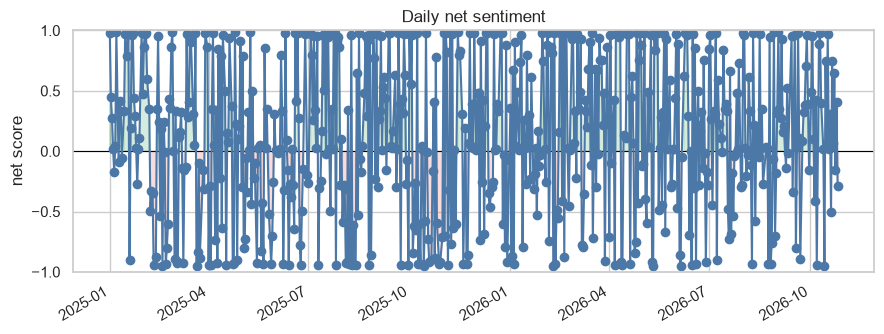

In [9]:
daily = result.groupby("date").agg(net=("net_score", "mean"), n=("net_score", "size")).reset_index()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.axhline(0, color="black", lw=0.8)
ax.plot(daily["date"], daily["net"], marker="o", color="#4c78a8")
ax.fill_between(daily["date"], daily["net"], 0, where=daily["net"] >= 0, color=PALETTE["positive"], alpha=0.2)
ax.fill_between(daily["date"], daily["net"], 0, where=daily["net"] < 0,  color=PALETTE["negative"], alpha=0.2)
ax.set_ylim(-1, 1); ax.set_title("Daily net sentiment"); ax.set_ylabel("net score")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

### 5.4 Most negative comments (what to fix first)

In [10]:
pd.set_option("display.max_colwidth", 120)
result.nsmallest(5, "net_score")[["platform", "date", TEXT_COL, "negative"]].round(3)

,platform,date,comment,negative
1347,Amazon,2026-08-22,"i regret buying these leggings: the ease of use is really poor. very disappointed, the customer service is mediocre ...",0.962
1009,Amazon,2026-04-05,Honestly the heat distribution is mediocre at best. I regret buying this cast iron skillet: the cleanup is disappoin...,0.961
401,Amazon,2025-07-01,Honestly the capacity is a joke. I regret buying this toaster: the cleanup is disappointing. I want a refund!!,0.961
126,Amazon,2025-03-02,Unfortunately the instructions are terrible. Nothing like the listing photos. I regret buying this moisturizer: the ...,0.961
674,Amazon,2025-11-10,the price is a joke. had to request a refund within the first week. honestly the comfort is not good at all. honestl...,0.960


### 5.5 Low-confidence predictions (candidates for human review)

In [11]:
review = result[result["needs_review"]].sort_values("confidence")
print(f"{len(review)} of {len(result)} predictions are below {LOW_CONF:.0%} confidence")
review[[TEXT_COL, "sentiment", "confidence"] + LABELS].round(2)

164 of 1500 predictions are below 60% confidence


,comment,sentiment,confidence,negative,neutral,positive
711,The value for the money is average. Works with most of my devices but not all of them. The compatibility is impressi...,positive,0.35,0.34,0.31,0.35
1387,"The portability is passable. It's fine for the price, just not exceptional. The performance is really good, but the ...",neutral,0.36,0.29,0.36,0.35
332,"Bought this board game for my husband. The age appropriateness is solid, but the build quality is pretty poor. It's ...",negative,0.36,0.36,0.33,0.31
72,"My one complaint is that the customer service is not perfect. Can't fault it, the ease of use is great. For the pric...",negative,0.36,0.36,0.33,0.31
786,"Got this as a replacement for my old one. It's fine for the price, just not exceptional. The performance is great, b...",negative,0.37,0.37,0.34,0.29
...,...,...,...,...,...,...
443,"Picked this up on sale. The size accuracy is impressive, but the softness is pretty poor.",negative,0.60,0.60,0.31,0.10
831,Ordered this blender after reading a bunch of reviews. Overall the value for the money is decent but nothing special...,positive,0.60,0.05,0.36,0.60
807,"The comfort is great, but the assembly is pretty poor. Might work better for someone else.",negative,0.60,0.60,0.31,0.09
606,"I'd say the value for the money is okay. Not much to say, the bluetooth connection is okay. Might work better for so...",positive,0.60,0.04,0.36,0.60


## 6. Sanity check against hand labels


Accuracy: 81.40%

              precision    recall  f1-score   support

    negative       0.80      0.98      0.88       532
     neutral       1.00      0.17      0.29       319
    positive       0.81      0.99      0.89       649

    accuracy                           0.81      1500
   macro avg       0.87      0.71      0.69      1500
weighted avg       0.85      0.81      0.76      1500



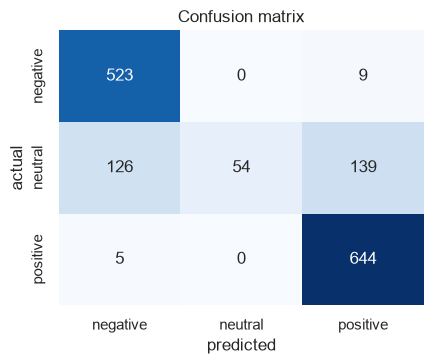

,comment,true_label,sentiment,confidence
3,"The stability is really good, but the size is lacking. Honestly the build quality is fine. Might work better for som...",neutral,positive,0.81
13,Got these as a replacement for my old one. At least the sound quality is decent. The comfort is far below what I exp...,negative,positive,0.41
21,"The ease of cleaning is solid, but the material is pretty poor.",neutral,negative,0.79
22,"The weight is impressive, but the heat distribution is pretty poor.",neutral,negative,0.67
27,"Cooks okay once you get used to the hot spots. The handles are average. The weight is so-so. Fine for the price, but...",neutral,positive,0.68
...,...,...,...,...
1476,"Overall the value for the money is okay, nothing more. I'd say the fun factor is passable. 🤷",neutral,positive,0.89
1481,"The sizing is really good, but the color accuracy is pretty poor. Fits okay but the fabric is thinner than I hoped. ...",neutral,positive,0.87
1482,"Picked this up on sale. Honestly the overall quality is okay. The fabric is solid, but the ease of use is pretty poo...",neutral,positive,0.45
1491,"The instructions are solid, but the noise level is lacking. Not bad, not great.",neutral,negative,0.69


In [12]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

DEMO_LABELS = [
    "positive", "positive", "negative", "positive", "neutral",
    "positive", "negative", "positive", "negative", "positive",
    "neutral",  "negative", "positive", "negative", "negative",
    "positive", "neutral",  "negative", "positive", "neutral",
]

if "label" in result.columns:
    result["true_label"] = result["label"].str.lower()
elif len(result) == len(DEMO_LABELS):
    result["true_label"] = DEMO_LABELS
else:
    result["true_label"] = np.nan
    print("No labels available: skipping evaluation.")

if result["true_label"].notna().any():
    y_true, y_pred = result["true_label"], result["sentiment"]
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.2%}\n")
    print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    fig, ax = plt.subplots(figsize=(4.5, 3.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title("Confusion matrix")
    plt.tight_layout(); plt.show()

    wrong = result[result["true_label"] != result["sentiment"]]
    display(wrong[[TEXT_COL, "true_label", "sentiment", "confidence"]].round(2))

## 7. Try your own reviews

In [13]:
def analyze(*reviews: str) -> pd.DataFrame:
    """Score one or more reviews and print a readable summary."""
    texts = [normalise(r) for r in reviews]
    out = predict(texts)
    out.insert(0, "review", reviews)
    for _, r in out.iterrows():
        print(f"{r['sentiment'].upper():9s} ({r['confidence']:.0%})  {r['review']}")
    return out.round(3)

analyze(
    "Absolutely love this product, best update yet 😍",
    "Support never answered my ticket. Unacceptable.",
    "It works. Nothing more, nothing less.",
    "Great, another crash. Just what I needed today.",       # sarcasm: a known weak spot
)

POSITIVE  (99%)  Absolutely love this product, best update yet 😍
NEGATIVE  (94%)  Support never answered my ticket. Unacceptable.
POSITIVE  (81%)  It works. Nothing more, nothing less.
NEGATIVE  (48%)  Great, another crash. Just what I needed today.


,review,negative,neutral,positive,sentiment,confidence
0,"Absolutely love this product, best update yet 😍",0.005,0.008,0.987,positive,0.987
1,Support never answered my ticket. Unacceptable.,0.935,0.059,0.006,negative,0.935
2,"It works. Nothing more, nothing less.",0.019,0.172,0.809,positive,0.809
3,"Great, another crash. Just what I needed today.",0.478,0.208,0.314,negative,0.478


## 8. Export results

In [14]:
export_cols = ["platform", "date", TEXT_COL, "sentiment", "confidence",
               "negative", "neutral", "positive", "net_score", "needs_review"]
result[export_cols].round(4).to_csv("sentiment_results.csv", index=False)
print("Saved sentiment_results.csv")

Saved sentiment_results.csv


In [16]:
RUN_FINETUNE = True    # flip to True once your data has a `label` column and enough rows

def fine_tune(data: pd.DataFrame, text_col=TEXT_COL, label_col="label",
              base_model=MODEL_ID, out_dir="./sentiment-finetuned",
              epochs=3, lr=2e-5, batch_size=16):
    from sklearn.model_selection import train_test_split
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                              TrainingArguments, Trainer)

    label2id = {l: i for i, l in enumerate(LABELS)}
    id2label = {i: l for l, i in label2id.items()}

    data = data[[text_col, label_col]].dropna().copy()
    data["y"] = data[label_col].str.lower().map(label2id)
    data["x"] = data[text_col].map(normalise)
    train_df, val_df = train_test_split(data, test_size=0.2, stratify=data["y"], random_state=42)

    tok = AutoTokenizer.from_pretrained(base_model)
    model = AutoModelForSequenceClassification.from_pretrained(
        base_model, num_labels=3, id2label=id2label, label2id=label2id, ignore_mismatched_sizes=True)

    class DS(torch.utils.data.Dataset):
        def __init__(self, d):
            self.enc = tok(list(d["x"]), truncation=True, max_length=MAX_LEN, padding=True)
            self.y = list(d["y"])
        def __len__(self): return len(self.y)
        def __getitem__(self, i):
            item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
            item["label"] = torch.tensor(self.y[i])
            return item

    def metrics(p):
        from sklearn.metrics import accuracy_score, f1_score
        preds = p.predictions.argmax(-1)
        return {"accuracy": accuracy_score(p.label_ids, preds),
                "macro_f1": f1_score(p.label_ids, preds, average="macro")}

    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=batch_size,
        eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True,
        metric_for_best_model="macro_f1", weight_decay=0.01, report_to="none", logging_steps=10)

    trainer = Trainer(model=model, args=args, train_dataset=DS(train_df),
                      eval_dataset=DS(val_df), compute_metrics=metrics)
    trainer.train()
    print(trainer.evaluate())
    trainer.save_model(out_dir); tok.save_pretrained(out_dir)
    return trainer

if RUN_FINETUNE:
    assert "label" in df.columns, "Add a 'label' column (negative/neutral/positive) to your CSV first."
    trainer = fine_tune(df)
else:
    print("Fine-tuning skipped (RUN_FINETUNE = False).")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.003106,0.000475,1.000000,1.000000
2,0.000550,0.000247,1.000000,1.000000
3,0.000484,0.000211,1.000000,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.000484,0.000475,3,1.000000,1.000000


{'eval_loss': 0.00047530492884106934, 'eval_accuracy': 1.0, 'eval_macro_f1': 1.0}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]